# SPLICE-Ptycho demo

Pretrained single-pattern reconstruction with the SPLICE framework on the simulated AD_LTEM test region:

1. load one diffraction pattern,
2. show the SPLICE views (band-resolved intensity, even lag, odd lag) and the detector signals,
3. reconstruct every test pattern independently with the full network,
4. show amplitude and phase patches and the stitched test field.

No training is needed. The simulated data are created on first use (`python main.py --mode generate`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from datasets import prepare_ad_ltem
from models import load_checkpoint
from simulation import generate_ad_ltem_dataset
from utils import (disable_tf32, evaluate, format_average_metrics, format_metrics, plot_patch_comparison,
                   plot_splice_views, plot_stitched, reconstruct_patches, select_device)

disable_tf32()
device = select_device()
data_root, assets = Path("data"), Path("simulation/assets")
if not (data_root / "75_diff.npy").exists():
    generate_ad_ltem_dataset(assets / "amplitude.tiff", assets / "phase.tiff", assets / "probe.npy", data_root,
                             paper_counts=assets / "ad_ltem_counts.npz")
test_set = prepare_ad_ltem(data_root).test_set
model, checkpoint = load_checkpoint("checkpoints/ad_ltem.pth", device)
print(f"{len(test_set.diffraction)} test patterns ({test_set.grid_size} x {test_set.grid_size} scan positions), device {device}")
print(f"parameters {sum(p.numel() for p in model.parameters()):,}, best validation epoch {checkpoint['best_epoch']}")

144 test patterns (12 x 12 scan positions), device cuda
parameters 2,131,551, best validation epoch 38


## 1-2. One diffraction pattern and its SPLICE views

SPLICE splits the pattern into three soft radial bands (central disc, inner annulus, outer region) calibrated from the training energy. Each band gives an intensity view with its own learned gain and smooth saturation, and the even and odd lag views (real and imaginary part of the inverse Fourier transform of the band). The odd view keeps the Friedel asymmetry of the pattern at every lag. The integrated band signals condition the network through FiLM. The lag maps are shown on a signed log scale.

detector radii (px): [1.51, 5.27]
band gains: [0.089, 5.892, 294.343]


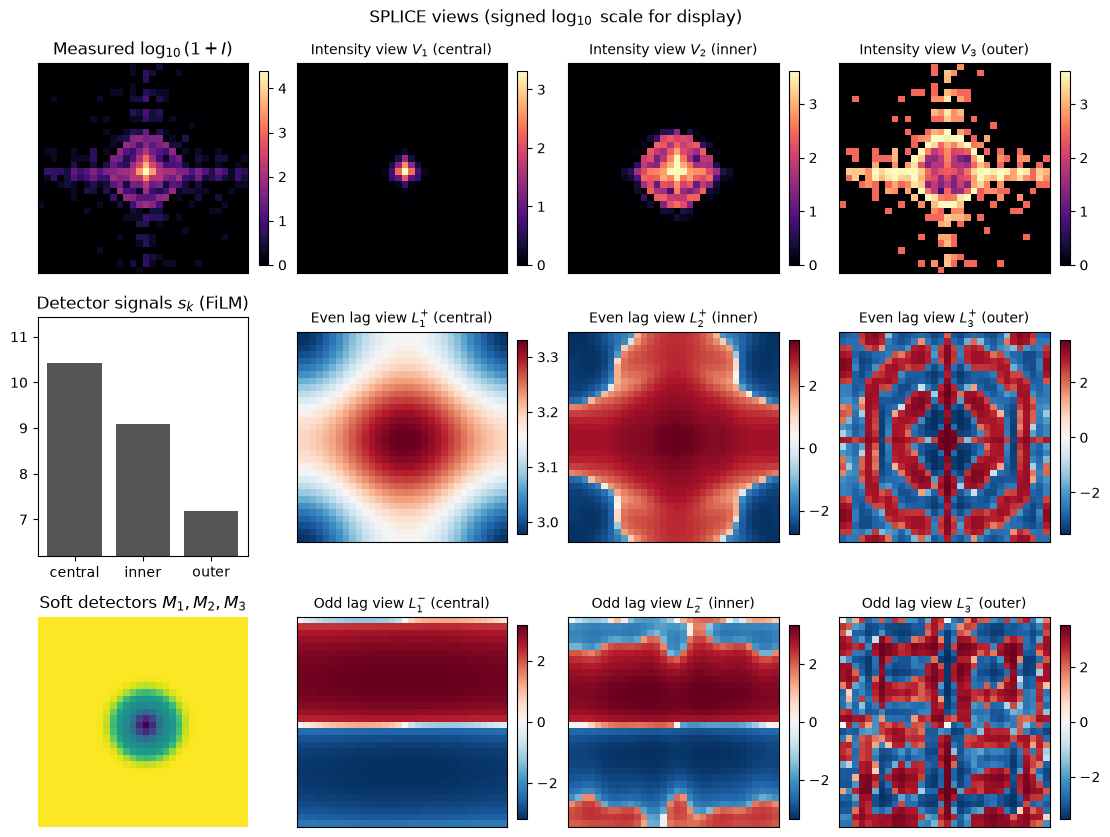

In [2]:
index = 77
pattern = test_set.diffraction[index]
with torch.no_grad():
    s = model.splice
    print("detector radii (px):", [round(float(b), 2) for b in s.initial_boundaries * torch.exp(0.5 * torch.tanh(s.boundary_offset))])
    print("band gains:", [round(float(g), 3) for g in s.initial_gains * s.relative_gains()])
plot_splice_views(model, pattern)
plt.show()

## 3. Single-pattern reconstruction of every test position

In [3]:
amplitude, phase = reconstruct_patches(model, test_set.diffraction, checkpoint["amplitude_range"])
result = evaluate("ad_ltem", test_set, amplitude, phase, checkpoint["amplitude_range"], checkpoint["phase_range"])
for name in ("amplitude", "phase"):
    print(f"patch    {name:9s} {format_average_metrics(result['patch'][name])}")
for name in ("amplitude", "phase"):
    print(f"stitched {name:9s} {format_metrics(result['stitched'][name])}")

patch    amplitude MSE 3.836e-02 +- 3.561e-02 | MAE 4.537e-02 +- 3.770e-02 | SSIM 0.8358 +- 0.1443 | PSNR 16.74 +- 6.23 dB
patch    phase     MSE 1.041e-02 +- 7.430e-03 | MAE 7.398e-02 +- 3.274e-02 | SSIM 0.7122 +- 0.1327 | PSNR 17.22 +- 3.12 dB
stitched amplitude MSE 1.397e-02   MAE 3.472e-02 | SSIM 0.8469   PSNR 18.55 dB
stitched phase     MSE 4.960e-03   MAE 5.305e-02 | SSIM 0.7925   PSNR 19.39 dB


## 4. Patches and the stitched test field

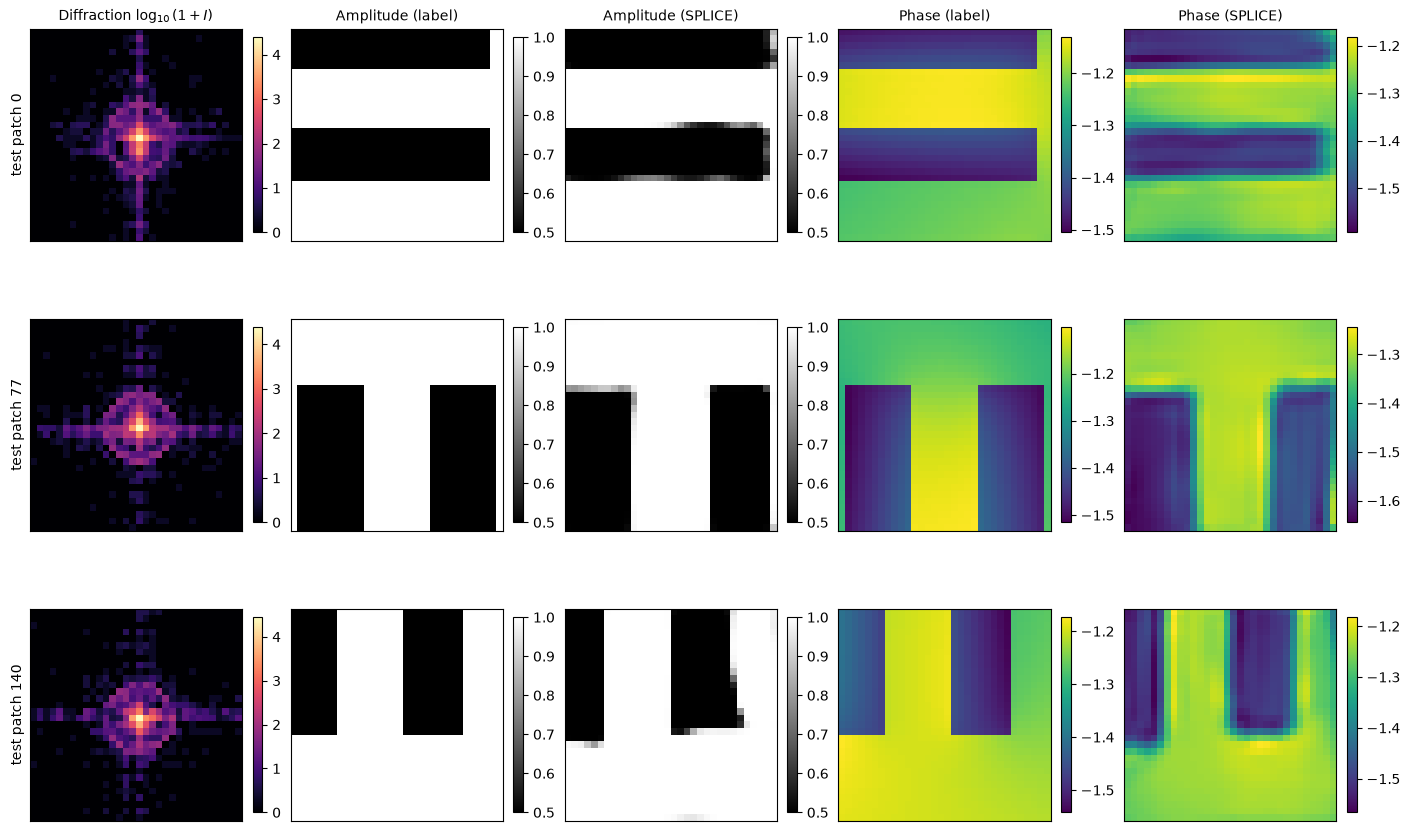

In [4]:
plot_patch_comparison(test_set, amplitude, phase, indices=(0, 77, 140))
plt.show()

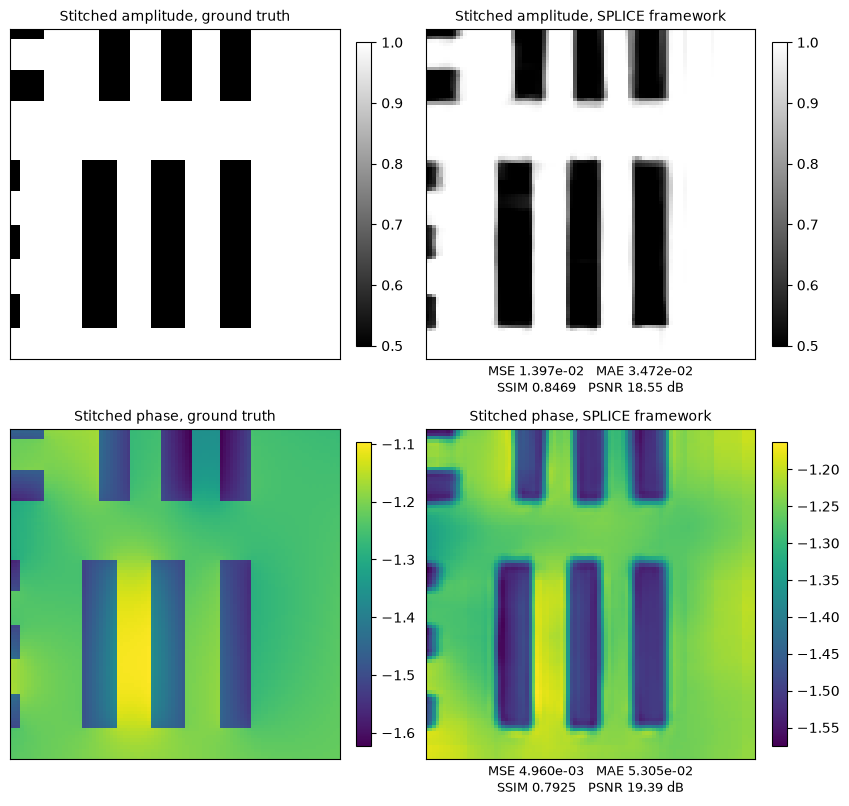

In [5]:
plot_stitched(result["images"], result["stitched"])
plt.show()

The experimental X-ray checkpoint is used the same way: download the two PtychoNN data files into `data/` (README) and run `python main.py --dataset experimental --mode test`.